In [32]:
# Import libraries
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
API_KEY = "YOUR_API_KEY"  # Replace with your actual OpenWeatherMap API key
city="Pune"
country="IN"
url = "https://api.openweathermap.org/data/2.5/forecast"
params={
    "q": f"{city},{country}",
    "appid": API_KEY,
    "units": "metric"
}

In [34]:
response = requests.get(url, params=params,timeout=30)

print(response.status_code)

if response.status_code==200:
    weather_data=response.json()
else:
    print("Error fetching data from API",response.text)

200


In [35]:
# Inspect the api response

print("City information:")
print(weather_data["city"])

print("\nFirst forecast record:")
print(weather_data["list"][0])

City information:
{'id': 1259229, 'name': 'Pune', 'coord': {'lat': 18.5196, 'lon': 73.8553}, 'country': 'IN', 'population': 9999, 'timezone': 19800, 'sunrise': 1791593808, 'sunset': 1791636376}

First forecast record:
{'dt': 1791622800, 'main': {'temp': 34.06, 'feels_like': 31.86, 'temp_min': 34.06, 'temp_max': 34.97, 'pressure': 1013, 'sea_level': 1013, 'grnd_level': 938, 'humidity': 18, 'temp_kf': -0.91, 'dew_point': 6.4}, 'weather': [{'id': 800, 'main': 'Clear', 'description': 'clear sky', 'icon': '01d'}], 'clouds': {'all': 0}, 'wind': {'speed': 0.35, 'deg': 331, 'gust': 2.1}, 'visibility': 10000, 'pop': 0, 'sys': {'pod': 'd'}, 'dt_txt': '2026-10-10 09:00:00'}


In [36]:
records = []

for item in weather_data["list"]:
    records.append({
        "datetime": item["dt"],
        "temperature": item["main"].get("temp"),
        "humidity": item["main"].get("humidity"),
        "wind_speed": item["wind"].get("speed"),
        "precipitation": item.get("rain", {}).get("3h", 0),
        "pressure": item["main"].get("pressure"),
        "clouds": item.get("clouds", {}).get("all"),
        "weather": item["weather"][0].get("description")
    })

df = pd.DataFrame(records)

df.head()

,datetime,temperature,humidity,wind_speed,precipitation,pressure,clouds,weather
0,1791622800,34.06,18,0.35,0,1013,0,clear sky
1,1791633600,31.29,34,2.95,0,1011,12,few clouds
2,1791644400,26.91,58,2.30,0,1013,90,overcast clouds
3,1791655200,28.08,60,1.24,0,1014,72,broken clouds
4,1791666000,26.88,61,1.97,0,1012,34,scattered clouds


In [37]:
#Convert Unix timestamps to Indian Standard Time
df["datetime"] = pd.to_datetime(
    df["datetime"], unit="s", utc=True
).dt.tz_convert("Asia/Kolkata")

# Remove duplicate timestamps
df = df.drop_duplicates(subset="datetime")

# Sort records by time
df = df.sort_values("datetime").reset_index(drop=True)

# Convert weather measurements to numeric values
numeric_columns = [
    "temperature", "humidity", "wind_speed",
    "precipitation", "pressure", "clouds"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Fill missing numerical values with their column median
df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].median()
)

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset shape:", df.shape)

df.head()

Missing values after cleaning:
datetime         0
temperature      0
humidity         0
wind_speed       0
precipitation    0
pressure         0
clouds           0
weather          0
dtype: int64

Cleaned dataset shape: (40, 8)


,datetime,temperature,humidity,wind_speed,precipitation,pressure,clouds,weather
0,2026-10-10 14:30:00+05:30,34.06,18,0.35,0,1013,0,clear sky
1,2026-10-10 17:30:00+05:30,31.29,34,2.95,0,1011,12,few clouds
2,2026-10-10 20:30:00+05:30,26.91,58,2.30,0,1013,90,overcast clouds
3,2026-10-10 23:30:00+05:30,28.08,60,1.24,0,1014,72,broken clouds
4,2026-10-11 02:30:00+05:30,26.88,61,1.97,0,1012,34,scattered clouds


In [38]:
# Perform basic statistical analysis on the cleaned dataset

print("Average temperature:", round(df["temperature"].mean(), 2), "°C")
print("Maximum temperature:", round(df["temperature"].max(), 2), "°C")
print("Minimum temperature:", round(df["temperature"].min(), 2), "°C")

print("\nAverage humidity:", round(df["humidity"].mean(), 2), "%")
print("Average wind speed:", round(df["wind_speed"].mean(), 2), "m/s")
print("Total forecast precipitation:", round(
    df["precipitation"].sum(), 2), "mm")

Average temperature: 28.28 °C
Maximum temperature: 35.16 °C
Minimum temperature: 23.06 °C

Average humidity: 43.08 %
Average wind speed: 2.1 m/s
Total forecast precipitation: 0 mm


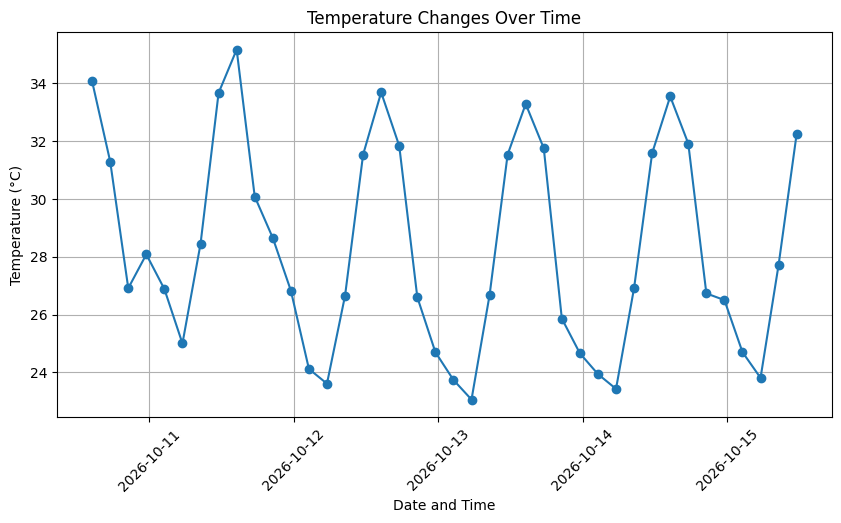

In [39]:
# Visualize temperature changes over time
plt.figure(figsize=(10, 5))
plt.plot(df['datetime'],df['temperature'],marker="o")

plt.title('Temperature Changes Over Time')
plt.xlabel('Date and Time')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

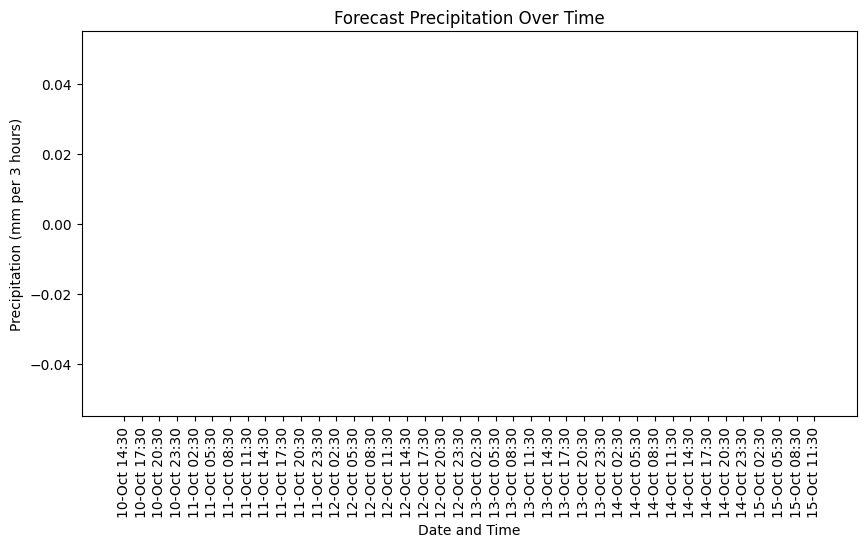

In [40]:
# Visualize precipitation over time
plt.figure(figsize=(10, 5))
plt.bar(
    df['datetime'].dt.strftime('%d-%b %H:%M'),
    df['precipitation']
)

plt.title('Forecast Precipitation Over Time')
plt.xlabel('Date and Time')
plt.ylabel('Precipitation (mm per 3 hours)')
plt.xticks(rotation=90)
plt.show()

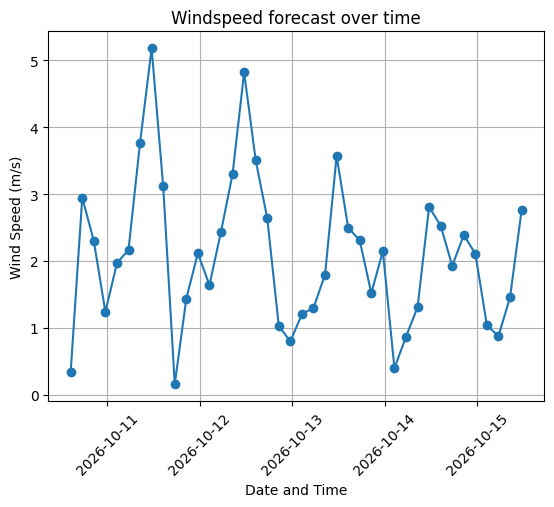

In [41]:
# Visualise the wind speed 
plt.plot(
    df['datetime'],
    df['wind_speed'],
    marker="o"
)
plt.title("Windspeed forecast over time")
plt.xlabel("Date and Time")
plt.ylabel("Wind Speed (m/s)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [42]:
df['date'] = df['datetime'].dt.date

daily = df.groupby('date').agg({
    "temperature": ["mean", "min", "max"],
    "humidity": "mean",
    "wind_speed":"mean",
    "precipitation": "sum"
})

daily.columns = [
    "avg_temperature",
    "min_temperature",
    "max_temperature",
    "avg_humidity",
    "avg_wind_speed",
    "total_precipitation"
]

daily = daily.round(2)
display(daily)

,avg_temperature,min_temperature,max_temperature,avg_humidity,avg_wind_speed,total_precipitation
date,,,,,,
2026-10-10,30.08,26.91,34.06,42.50,1.71,0
2026-10-11,29.34,25.00,35.16,43.50,2.49,0
2026-10-12,27.84,23.61,33.68,40.12,2.52,0
2026-10-13,27.57,23.06,33.28,42.00,2.04,0
2026-10-14,28.07,23.43,33.54,44.75,1.79,0
2026-10-15,27.12,23.81,32.25,47.50,1.54,0


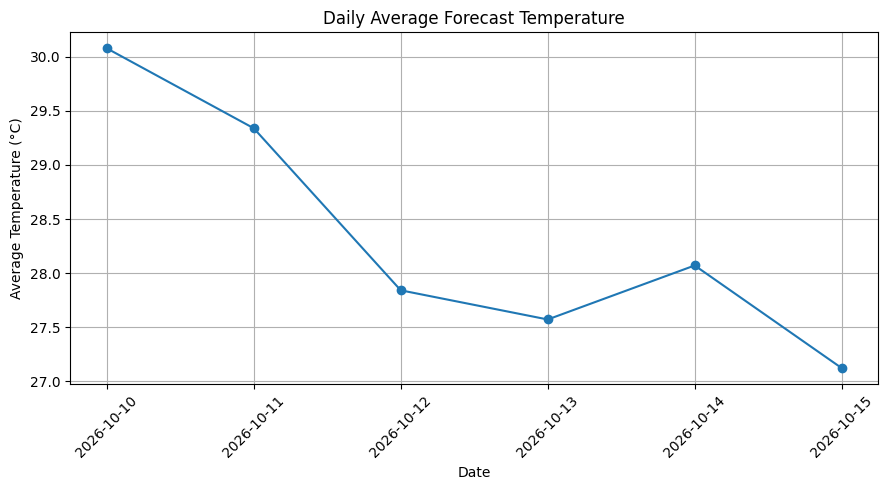

In [43]:
# Plot daily average temperature
plt.figure(figsize=(9, 5))

plt.plot(
    daily.index.astype(str),
    daily["avg_temperature"],
    marker="o"
)

plt.title("Daily Average Forecast Temperature")
plt.xlabel("Date")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

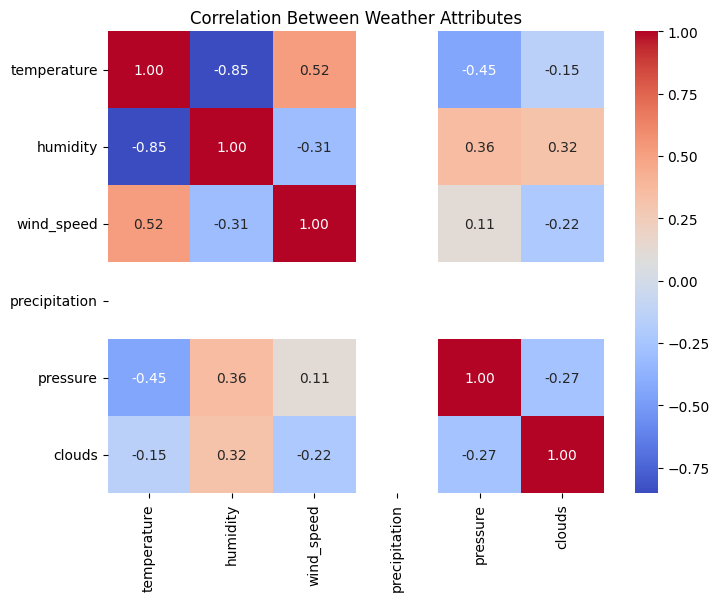

In [44]:
#Coorelation between weather columns
weather_columns = [
    "temperature", "humidity", "wind_speed",
    "precipitation", "pressure", "clouds"
]

correlation = df[weather_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Weather Attributes")
plt.show()

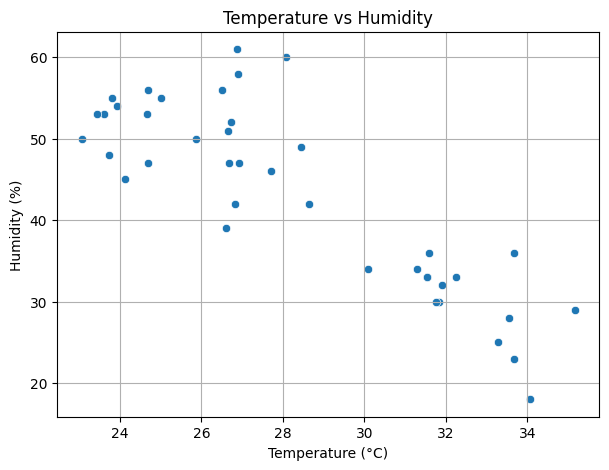

In [45]:
# Temp vs humidity

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="temperature",
    y="humidity"
)

plt.title("Temperature vs Humidity")
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.grid(True)
plt.show()

In [46]:
#  Plot for multiple cities
cities = ["Bengaluru", "Mumbai", "Pune", "Delhi"]

locations = []

for city_name in cities:
    params = {
        "q": f"{city_name},IN",
        "appid": API_KEY,
        "units": "metric"
    }

    response = requests.get(url, params=params, timeout=30)

    if response.status_code == 200:
        data = response.json()

        locations.append({
            "city": data["city"]["name"],
            "latitude": data["city"]["coord"]["lat"],
            "longitude": data["city"]["coord"]["lon"],
            "temperature": data["list"][0]["main"]["temp"],
            "humidity": data["list"][0]["main"]["humidity"]
        })
    else:
        print("Could not retrieve data for", city_name)

locations_df = pd.DataFrame(locations)

display(locations_df)

,city,latitude,longitude,temperature,humidity
0,Bengaluru,12.9762,77.6033,28.97,43
1,Mumbai,19.0144,72.8479,30.46,61
2,Pune,18.5196,73.8553,34.06,18
3,Delhi,28.6667,77.2167,32.27,51


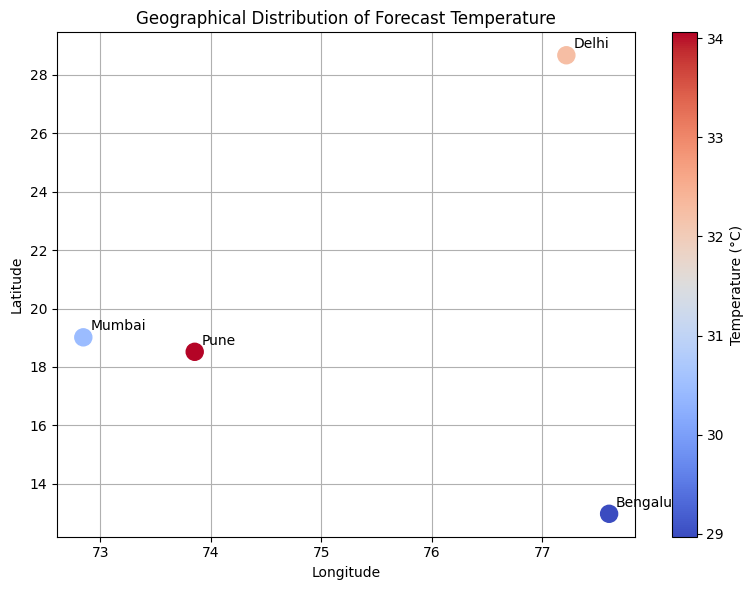

In [47]:
plt.figure(figsize=(8, 6))

points = plt.scatter(
    locations_df["longitude"],
    locations_df["latitude"],
    c=locations_df["temperature"],
    s=150,
    cmap="coolwarm"
)

for _, row in locations_df.iterrows():
    plt.annotate(
        row["city"],
        (row["longitude"], row["latitude"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.colorbar(points, label="Temperature (°C)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Forecast Temperature")
plt.grid(True)
plt.tight_layout()
plt.show()

In [48]:
# Final summary of the weather data for primary city
summary = pd.DataFrame({
    "Statistic": [
        "Average Temperature (°C)",
        "Maximum Temperature (°C)",
        "Minimum Temperature (°C)",
        "Average Humidity (%)",
        "Average Wind Speed (m/s)",
        "Total Forecast Precipitation (mm)"
    ],
    "Value": [
        round(df["temperature"].mean(), 2),
        round(df["temperature"].max(), 2),
        round(df["temperature"].min(), 2),
        round(df["humidity"].mean(), 2),
        round(df["wind_speed"].mean(), 2),
        round(df["precipitation"].sum(), 2)
    ]
})

display(summary)

,Statistic,Value
0,Average Temperature (°C),28.28
1,Maximum Temperature (°C),35.16
2,Minimum Temperature (°C),23.06
3,Average Humidity (%),43.08
4,Average Wind Speed (m/s),2.10
5,Total Forecast Precipitation (mm),0.00
